# Imports

In [1]:
import json
from collections import deque
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx            # preverjanje in izvoz v GraphML

rng = np.random.default_rng(1)
IZVOZ = Path("izvoz")            # mapa za izvožene grafe
IZVOZ.mkdir(exist_ok=True)

# Funkcije

In [2]:
# --- Graf in metrike z vaje 07 ---
class Graf:
    def __init__(self):
        self.sosedje = {}

    def dodaj_vozlisce(self, v):
        self.sosedje.setdefault(v, set())

    def dodaj_povezavo(self, u, v):
        if u == v:
            return
        self.dodaj_vozlisce(u)
        self.dodaj_vozlisce(v)
        self.sosedje[u].add(v)
        self.sosedje[v].add(u)

    def odstrani_povezavo(self, u, v):
        self.sosedje[u].discard(v)
        self.sosedje[v].discard(u)

    def n(self):
        return len(self.sosedje)

    def m(self):
        return sum(len(s) for s in self.sosedje.values()) // 2

    def stopnja(self, v):
        return len(self.sosedje[v])

    def povezave(self):
        return [(u, v) for u in self.sosedje for v in self.sosedje[u] if u < v]

    def __repr__(self):
        return f"Graf(n={self.n()}, m={self.m()})"


def lokalna_grucavost(G, v):
    s = list(G.sosedje[v])
    k = len(s)
    if k < 2:
        return 0.0
    e = sum(1 for i in range(k) for j in range(i + 1, k) if s[j] in G.sosedje[s[i]])
    return 2 * e / (k * (k - 1))


def povprecna_grucavost(G):
    return np.mean([lokalna_grucavost(G, v) for v in G.sosedje])


def bfs(G, izvor):
    d = {izvor: 0}
    vrsta = deque([izvor])
    while vrsta:
        u = vrsta.popleft()
        for w in G.sosedje[u]:
            if w not in d:
                d[w] = d[u] + 1
                vrsta.append(w)
    return d


def povprecna_pot(G):
    """Povprečna najkrajša pot na komponenti, ki vsebuje vozlišče 0."""
    vsota, parov = 0, 0
    for v in bfs(G, 0):
        d = bfs(G, v)
        vsota += sum(d.values())
        parov += len(d) - 1
    return vsota / parov


def obroc(n, k):
    G = Graf()
    for i in range(n):
        for j in range(1, k // 2 + 1):
            G.dodaj_povezavo(i, (i + j) % n)
    return G


# --- Generatorji ---
def watts_strogatz(n, k, p, rng=rng):
    """Obroč, v katerem vsako povezavo (i, i+j) z verjetnostjo p prevežemo na naključno vozlišče."""
    G = obroc(n, k)
    for j in range(1, k // 2 + 1):
        for i in range(n):
            u, v = i, (i + j) % n
            if rng.random() < p and v in G.sosedje[u]:
                w = int(rng.integers(n))
                while w == u or w in G.sosedje[u]:
                    w = int(rng.integers(n))
                G.odstrani_povezavo(u, v)
                G.dodaj_povezavo(u, w)
    return G


def barabasi_albert(n, m, rng=rng):
    """Preferenčno pripenjanje: vsako novo vozlišče se poveže z m obstoječimi,
    verjetnost izbire je sorazmerna s stopnjo."""
    G = Graf()
    for i in range(m + 1):                 # začetni poln graf z m + 1 vozlišči
        for j in range(i + 1, m + 1):
            G.dodaj_povezavo(i, j)
    krajisca = [v for e in G.povezave() for v in e]   # vsako vozlišče je zapisano k-krat
    for novo in range(m + 1, n):
        cilji = set()
        while len(cilji) < m:
            cilji.add(krajisca[rng.integers(len(krajisca))])
        for c in cilji:
            G.dodaj_povezavo(novo, c)
            krajisca += [novo, c]
    return G


# --- Izris ---
def krozna_razporeditev(G):
    v = sorted(G.sosedje)
    fi = 2 * np.pi * np.arange(len(v)) / len(v)
    return {u: np.array([np.cos(f), np.sin(f)]) for u, f in zip(v, fi)}


def fr_razporeditev(G, n_iter=200, rng=rng):
    """Fruchterman-Reingoldova razporeditev: odboj k^2/d med vsemi pari, privlak d^2/k po povezavah."""
    voz = sorted(G.sosedje)
    ind = {v: i for i, v in enumerate(voz)}
    E = np.array([(ind[u], ind[v]) for u, v in G.povezave()])
    N = len(voz)
    poz = rng.uniform(-1, 1, (N, 2))
    k = np.sqrt(4.0 / N)                       # optimalna razdalja (ploščina 2 x 2)
    T = 0.2
    for it in range(n_iter):
        dr = poz[:, None, :] - poz[None, :, :]
        d = np.linalg.norm(dr, axis=-1) + 1e-9
        premik = np.sum(dr / d[..., None] * (k**2 / d)[..., None], axis=1)
        de = poz[E[:, 0]] - poz[E[:, 1]]
        dd = np.linalg.norm(de, axis=1)[:, None] + 1e-9
        f = de / dd * dd**2 / k
        np.add.at(premik, E[:, 0], -f)
        np.add.at(premik, E[:, 1], f)
        dolz = np.linalg.norm(premik, axis=1)[:, None] + 1e-9
        poz += premik / dolz * np.minimum(dolz, T)  # premik omejimo s temperaturo
        T *= 0.98                                    # ohlajanje
    return {v: poz[ind[v]] for v in voz}


def narisi_graf(ax, G, poz, velikost=None):
    for u, v in G.povezave():
        ax.plot(*np.array([poz[u], poz[v]]).T, color="gray", lw=0.5, zorder=1)
    st = np.array([G.stopnja(v) for v in poz])
    xy = np.array(list(poz.values()))
    ax.scatter(xy[:, 0], xy[:, 1], s=velikost if velikost is not None else 3 + 2 * st,
               c=st, cmap="viridis", zorder=2)
    ax.set_aspect("equal")
    ax.axis("off")


# --- Izvoz in uvoz ---
def izvozi_csv(G, pot):
    with open(pot, "w") as f:
        f.write("vir,cilj\n")
        for u, v in G.povezave():
            f.write(f"{u},{v}\n")


def uvozi_csv(pot):
    G = Graf()
    with open(pot) as f:
        next(f)
        for vrstica in f:
            u, v = map(int, vrstica.split(","))
            G.dodaj_povezavo(u, v)
    return G


def izvozi_json(G, pot):
    with open(pot, "w") as f:
        json.dump({"vozlisca": sorted(G.sosedje), "povezave": G.povezave()}, f)


def uvozi_json(pot):
    G = Graf()
    with open(pot) as f:
        d = json.load(f)
    for v in d["vozlisca"]:
        G.dodaj_vozlisce(v)
    for u, v in d["povezave"]:
        G.dodaj_povezavo(u, v)
    return G


def v_networkx(G):
    H = nx.Graph()
    H.add_nodes_from(G.sosedje)
    H.add_edges_from(G.povezave())
    return H

# Testno območje

In [3]:
G0 = obroc(500, 10)
print(G0, f"C(0) = {povprecna_grucavost(G0):.3f}, L(0) = {povprecna_pot(G0):.2f}")
Gw = watts_strogatz(500, 10, 0.01)
print("WS p = 0.01:", Gw, "| prevezanih ≈", len(set(G0.povezave()) - set(Gw.povezave())))
Gb = barabasi_albert(2000, 2)
print("BA:", Gb, f"<k> = {2*Gb.m()/Gb.n():.2f}, k_max = {max(Gb.stopnja(v) for v in Gb.sosedje)}")

Graf(n=500, m=2500) C(0) = 0.667, L(0) = 25.45
WS p = 0.01: Graf(n=500, m=2500) | prevezanih ≈ 22
BA: Graf(n=2000, m=3997) <k> = 4.00, k_max = 76


# Naloga 1 - Slika 1

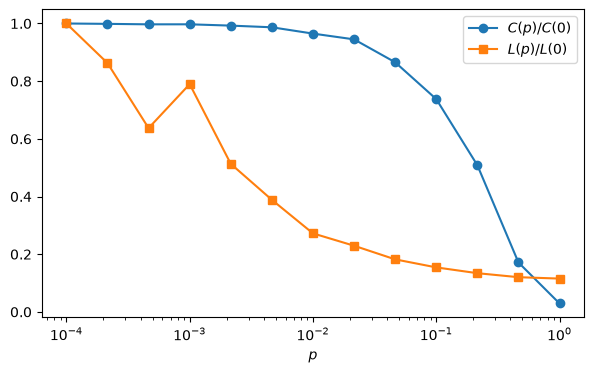

p = 1.0e-04: C/C0 = 1.000, L/L0 = 1.000
p = 2.2e-04: C/C0 = 0.999, L/L0 = 0.863
p = 4.6e-04: C/C0 = 0.997, L/L0 = 0.637
p = 1.0e-03: C/C0 = 0.997, L/L0 = 0.790
p = 2.2e-03: C/C0 = 0.993, L/L0 = 0.513
p = 4.6e-03: C/C0 = 0.987, L/L0 = 0.389
p = 1.0e-02: C/C0 = 0.965, L/L0 = 0.272
p = 2.2e-02: C/C0 = 0.945, L/L0 = 0.229
p = 4.6e-02: C/C0 = 0.866, L/L0 = 0.182
p = 1.0e-01: C/C0 = 0.738, L/L0 = 0.154
p = 2.2e-01: C/C0 = 0.509, L/L0 = 0.134
p = 4.6e-01: C/C0 = 0.171, L/L0 = 0.120
p = 1.0e+00: C/C0 = 0.029, L/L0 = 0.115


In [4]:
p_v = np.logspace(-4, 0, 13)
C0, L0 = povprecna_grucavost(G0), povprecna_pot(G0)
C_p, L_p = [], []
for p in p_v:
    Cs, Ls = [], []
    for _ in range(2):
        G = watts_strogatz(500, 10, p)
        Cs.append(povprecna_grucavost(G))
        Ls.append(povprecna_pot(G))
    C_p.append(np.mean(Cs) / C0)
    L_p.append(np.mean(Ls) / L0)
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
ax.semilogx(p_v, C_p, "o-", label="$C(p)/C(0)$")
ax.semilogx(p_v, L_p, "s-", label="$L(p)/L(0)$")
ax.set_xlabel("$p$")
ax.legend()
plt.show()
for p, c, l in zip(p_v, C_p, L_p):    # Preglednica 1
    print(f"p = {p:.1e}: C/C0 = {c:.3f}, L/L0 = {l:.3f}")

# Naloga 2 - Slika 2

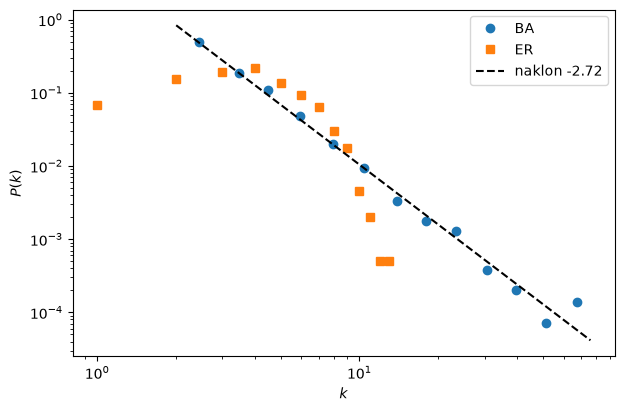

BA: <k> = 4.00, k_max = 76, delež k >= 20: 0.0175
ER: <k> = 4.00, k_max = 13, delež k >= 20: 0.0000
BA: C = 0.0171, ER: C = 0.0014


In [5]:
st_ba = np.array([Gb.stopnja(v) for v in Gb.sosedje])
G_er = nx.gnm_random_graph(Gb.n(), Gb.m(), seed=1)      # naključni graf z enakim n in m
st_er = np.array([d for _, d in G_er.degree()])
fig = plt.figure(figsize=(7, 4.5))
ax = fig.add_subplot(111)
robovi = np.unique(np.logspace(np.log10(2), np.log10(st_ba.max() + 1), 15).astype(int))
h, _ = np.histogram(st_ba, bins=robovi)
sredine = np.sqrt(robovi[1:] * robovi[:-1])
P_ba = h / np.diff(robovi) / len(st_ba)
izb = P_ba > 0
ax.loglog(sredine[izb], P_ba[izb], "o", label="BA")
k_er, N_er = np.unique(st_er, return_counts=True)
ax.loglog(k_er, N_er / len(st_er), "s", label="ER")
gama, A = np.polyfit(np.log10(sredine[izb]), np.log10(P_ba[izb]), 1)
kk = np.logspace(np.log10(2), np.log10(st_ba.max()), 50)
ax.loglog(kk, 10**A * kk**gama, "k--", label=f"naklon {gama:.2f}")
ax.set_xlabel("$k$")
ax.set_ylabel("$P(k)$")
ax.legend()
plt.show()
# Preglednica 2
for ime, s in (("BA", st_ba), ("ER", st_er)):
    print(f"{ime}: <k> = {s.mean():.2f}, k_max = {s.max()}, delež k >= 20: {np.mean(s >= 20):.4f}")
print(f"BA: C = {povprecna_grucavost(Gb):.4f}, ER: C = {nx.average_clustering(G_er):.4f}")

# Naloga 3 - Slika 3

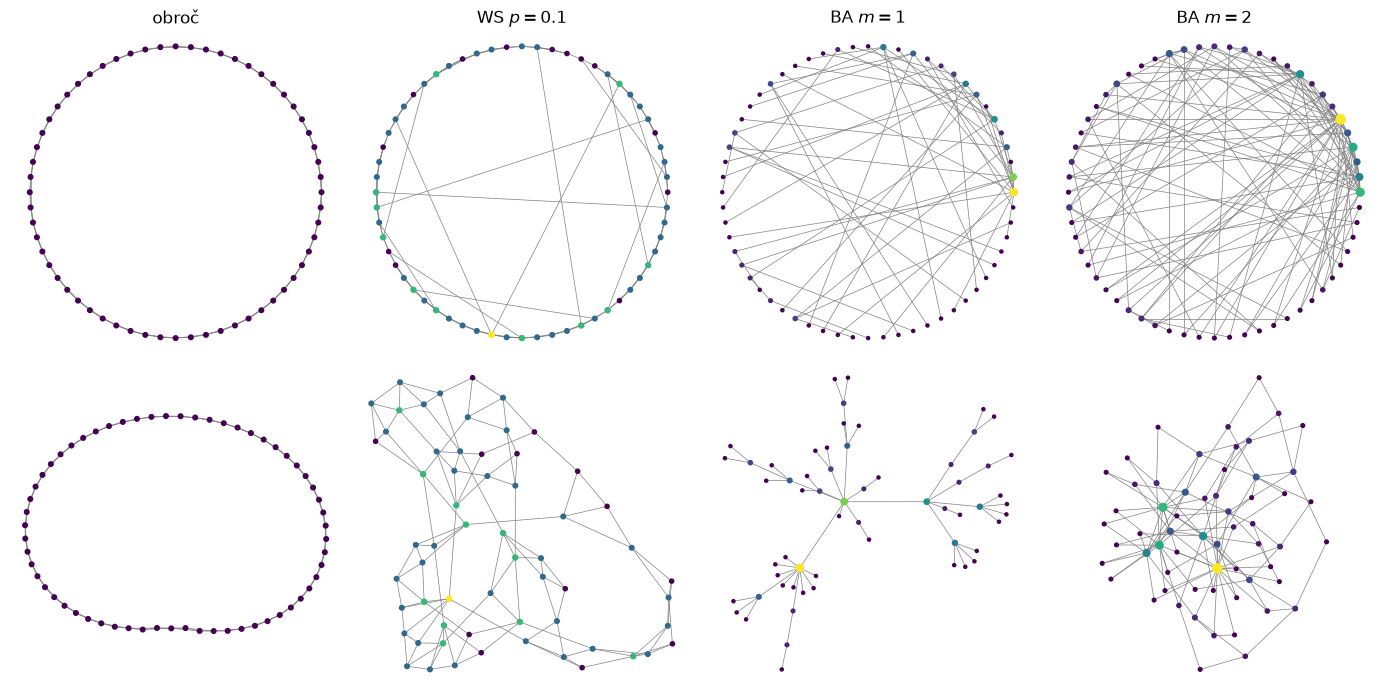

In [6]:
grafi = {"obroč": obroc(60, 4), "WS $p = 0.1$": watts_strogatz(60, 4, 0.1),
         "BA $m = 1$": barabasi_albert(60, 1), "BA $m = 2$": barabasi_albert(60, 2)}
fig = plt.figure(figsize=(14, 7))
for k, (ime, G) in enumerate(grafi.items()):
    ax = fig.add_subplot(2, 4, k + 1)
    narisi_graf(ax, G, krozna_razporeditev(G))
    ax.set_title(ime)
    ax = fig.add_subplot(2, 4, k + 5)
    narisi_graf(ax, G, fr_razporeditev(G))
fig.tight_layout()
plt.show()

# Naloga 4

In [7]:
izvozi_csv(Gb, IZVOZ / "ba.csv")
izvozi_json(Gb, IZVOZ / "ba.json")
nx.write_graphml(v_networkx(Gb), IZVOZ / "ba.graphml")
for ime, G2 in (("CSV", uvozi_csv(IZVOZ / "ba.csv")), ("JSON", uvozi_json(IZVOZ / "ba.json"))):
    enak = G2.sosedje == Gb.sosedje
    print(f"{ime}: {G2}, enak izvirniku: {enak}")
H = nx.read_graphml(IZVOZ / "ba.graphml")
print(f"GraphML: n = {H.number_of_nodes()}, m = {H.number_of_edges()}")
for f in sorted(IZVOZ.iterdir()):
    print(f"{f.name:12s} {f.stat().st_size / 1024:8.1f} kB")
print(f"matrika sosednosti (1 bajt na element): {Gb.n()**2 / 1024:.0f} kB")

CSV: Graf(n=2000, m=3997), enak izvirniku: True
JSON: Graf(n=2000, m=3997), enak izvirniku: True
GraphML: n = 2000, m = 3997
ba.csv           35.3 kB
ba.graphml      196.5 kB
ba.json          57.6 kB
matrika sosednosti (1 bajt na element): 3906 kB
